**Bahasa Indonesia**

# 02 — Quantum Chat: arsitektur, framing, biaya dan eksperimen

Notebook ini menelusuri pesan UTF-8 melalui engine aplikasi, membedakan
penerimaan dari konfirmasi ACK, serta menjalankan uji ideal dan berisik.
Seluruh angka tabel dihitung saat notebook dieksekusi.

---

**English**

# 02 — Quantum Chat: architecture, framing, costs, and experiments

This notebook follows UTF-8 messages through the application engine, distinguishes
receipt from ACK confirmation, and runs ideal and noisy trials. Every number in
the tables is computed when the notebook executes.


In [1]:
from pathlib import Path
import sys, platform, importlib.metadata as metadata
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'pyproject.toml').exists() and (p/'densechat').is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cirq, qsimcirq
from IPython.display import display
from IPython import get_ipython
get_ipython().run_line_magic('matplotlib', 'inline')
from scripts.notebook_support import style, save, COLORS, bilingual_table
style()
SEED = 20261106
print('Python:', platform.python_version(), '| seed:', SEED)
print({name: metadata.version(name) for name in ['cirq-core', 'qsimcirq', 'numpy', 'matplotlib']})


Python: 3.12.16 | seed: 20261106
{'cirq-core': '1.7.0', 'qsimcirq': '0.22.1', 'numpy': '2.5.4', 'matplotlib': '3.11.2'}


**Bahasa Indonesia**

## 1. Dua lapisan yang berbeda

Diagram menggambarkan alur logis dalam backend tepercaya. TCP lokal antara
terminal dan backend adalah komunikasi **klasik**, termasuk teks input.
Transfer A pada circuit adalah model quantum. Keduanya tidak boleh dicampur
untuk mengklaim payload fisik tanpa saluran atau biaya komunikasi nol.

---

**English**

## 1. Two distinct layers

The diagram shows the logical path inside a trusted backend. Local TCP between
the terminals and backend is **classical** communication, including input text.
A transfer in the circuit is a quantum model. The two must not be conflated to
claim physical payload delivery without a channel or zero communication costs.


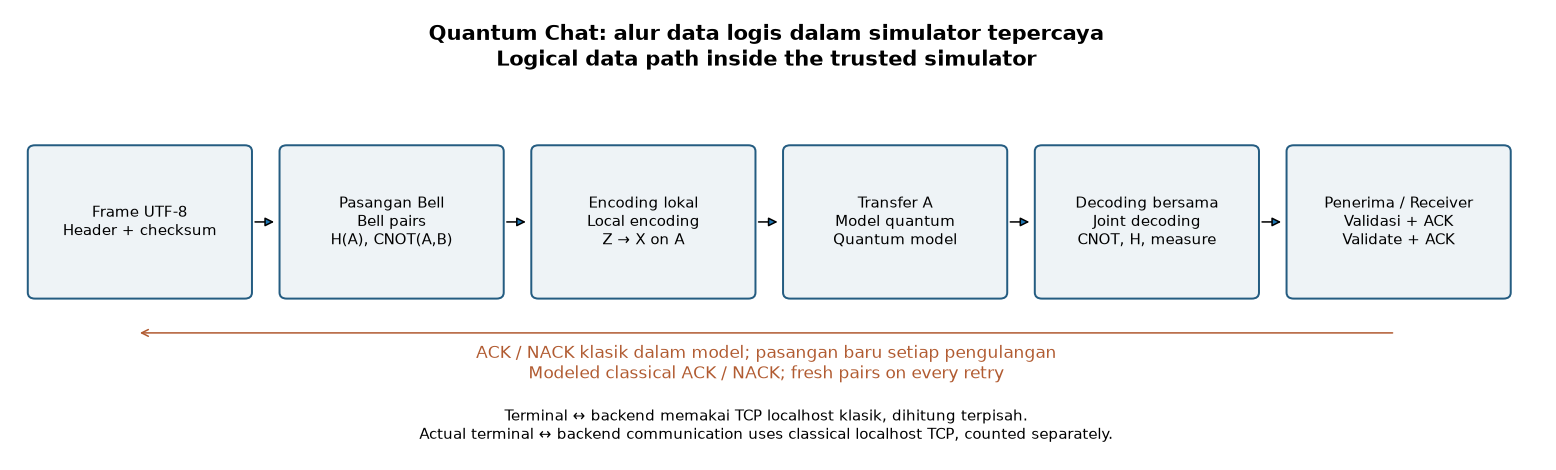

In [2]:
from scripts.notebook_support import architecture
fig = architecture()
save(fig, 'quantum_chat_architecture')
display(fig); plt.close(fig)


**Bahasa Indonesia**

## 2. Protokol byte dan roundtrip dua arah

Frame = header 15 byte + payload UTF-8 + SHA-256 32 byte. Header memuat
sequence dan panjang. Setiap dua bit memakai Bell pair baru. Endpoint
penerima hanya menerima byte hasil pengukuran, lalu memvalidasi frame.
Checksum tanpa kunci mendeteksi kerusakan tak sengaja, bukan autentikasi.

---

**English**

## 2. Byte protocol and two-way roundtrips

Frame = 15-byte header + UTF-8 payload + 32-byte SHA-256. The header contains
sequence and length. Each two bits use a fresh Bell pair. The receiving endpoint
gets only measured bytes, then validates the frame. An unkeyed checksum detects
accidental corruption; it is not authentication.


In [3]:
from densechat.session import ChatSession
from densechat.protocol import HEADER, ACK_SIZE, encode_message
session = ChatSession(seed=SEED)
for name in ('Bumi', 'Mars'):
    session.add_endpoint(name)
messages = [('Bumi','Mars','Hai! Apa kabarmu hari ini'), ('Mars','Bumi','Diterima, Bumi! 🌏'), ('Bumi','Mars','')]
delivery_rows = []
for sender, recipient, text in messages:
    result = session.send(sender, recipient, text)
    assert result.confirmed and result.received_text == text
    delivery_rows.append({'sender': sender, 'receiver': recipient, 'UTF-8 bytes': len(text.encode()),
                          'frame bytes': len(encode_message(text, result.sequence)), 'status': result.status,
                          'A transfers': result.resources['sent_a_qubits'], 'B distributions': result.resources['distributed_b_qubits'],
                          'ACK bits': result.resources['classical_ack_bits']})
display(bilingual_table(pd.DataFrame(delivery_rows)))
print('Byte header / Header bytes:', HEADER.size, '| Byte ACK / ACK bytes:', ACK_SIZE)


,pengirim / sender,penerima / receiver,byte UTF-8 / UTF-8 bytes,byte frame / frame bytes,status / status,transfer A / A transfers,distribusi B / B distributions,bit ACK / ACK bits
0,Bumi,Mars,25,72,CONFIRMED,288,288,600
1,Mars,Bumi,20,67,CONFIRMED,268,268,600
2,Bumi,Mars,0,47,CONFIRMED,188,188,600


Byte header / Header bytes: 15 | Byte ACK / ACK bytes: 75


**Bahasa Indonesia**

## 3. Biaya harus memasukkan overhead

Untuk L byte frame dan R attempts: 4LR Bell pair, 4LR transfer A,
4LR distribusi awal B, serta 600R bit ACK/NACK. Frame contoh 25-byte teks
memiliki 72 byte total, bukan hanya 25 byte payload. Model ini tidak memuat
kompresi, QML, corpus atau pre-shared key.

---

**English**

## 3. Costs must include overhead

For L frame bytes and R attempts: 4LR Bell pairs, 4LR A transfers, 4LR initial
B distributions, and 600R ACK/NACK bits. The 25-byte text example produces a
72-byte frame, rather than just 25 payload bytes. The model has no compression,
QML, corpus, or pre-shared key.


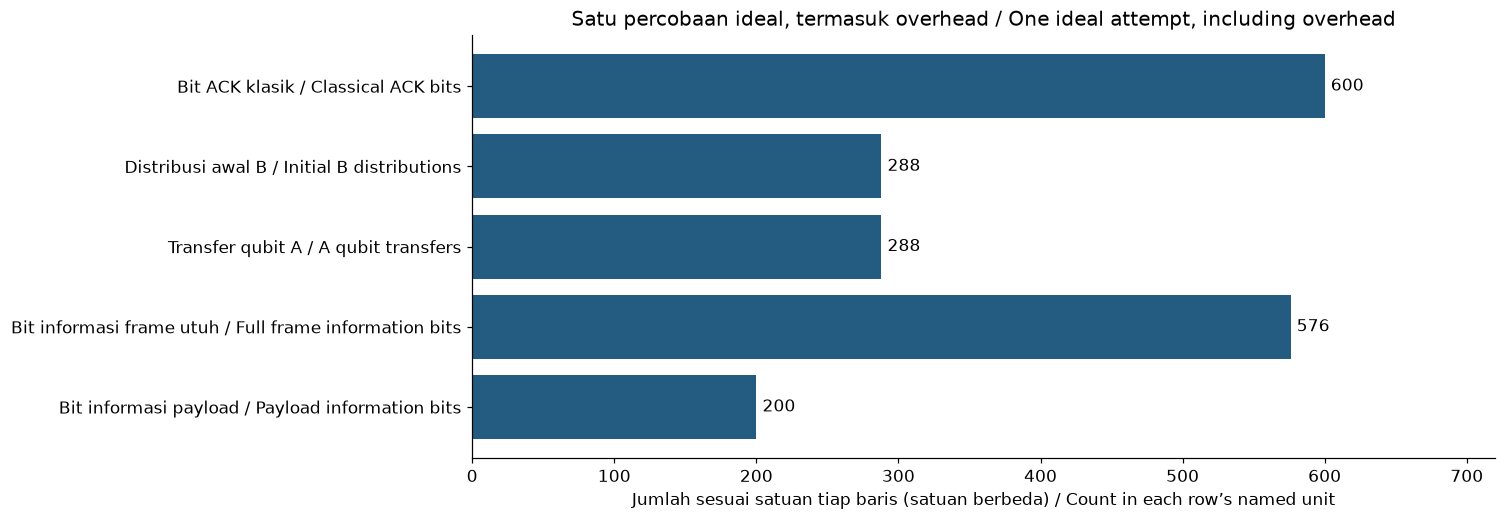

In [4]:
text = messages[0][2]
payload_bits = 8*len(text.encode())
frame_bits = 8*len(encode_message(text, 1))
costs = {'Bit informasi payload / Payload information bits': payload_bits, 'Bit informasi frame utuh / Full frame information bits': frame_bits,
         'Transfer qubit A / A qubit transfers': frame_bits//2, 'Distribusi awal B / Initial B distributions': frame_bits//2, 'Bit ACK klasik / Classical ACK bits': ACK_SIZE*8}
fig, ax = plt.subplots(figsize=(12,5))
bars = ax.barh(list(costs), list(costs.values()), color=COLORS[0])
ax.bar_label(bars, padding=4)
ax.set_xlabel('Jumlah sesuai satuan tiap baris (satuan berbeda) / Count in each row’s named unit')
ax.set_xlim(0, max(costs.values())*1.2)
ax.set_title('Satu percobaan ideal, termasuk overhead / One ideal attempt, including overhead')
save(fig, 'resource_accounting')
display(fig); plt.close(fig)


**Bahasa Indonesia**

## 4. Penerimaan berbeda dari konfirmasi

Pada demonstrasi berikut, semua bit ACK sengaja dibalik. Penerima dapat
memperoleh teks, tetapi pengirim tidak menerima ACK valid. Pengiriman ulang
tidak membuat entri riwayat baru untuk sequence/fingerprint yang sama.
Ini kontrol kegagalan protokol, bukan hasil probabilistik yang disembunyikan.

---

**English**

## 4. Receipt differs from confirmation

In the following demonstration every ACK bit is deliberately flipped. The receiver
can obtain the text while the sender never receives a valid ACK. Retries do not
create new history entries for the same sequence/fingerprint. This is a protocol
failure control, not a concealed probabilistic result.


In [5]:
lost_ack = ChatSession(seed=SEED, ack_noise=1.0, attempts=3)
for name in ('Bumi','Mars'):
    lost_ack.add_endpoint(name)
result = lost_ack.send('Bumi','Mars','Pesan diterima, ACK hilang')
assert result.received and not result.confirmed and len(lost_ack.history) == 1
display(bilingual_table(pd.DataFrame(result.events)))
print('Diterima penerima / Receiver accepted:', result.received, '| status pengirim / sender status:', result.status, '| pengiriman unik / unique deliveries:', len(lost_ack.history))


,percobaan / attempt,diterima / accepted,baru / fresh,ACK valid / valid ACK,kesalahan / error
0,1,True,True,False,None
1,2,True,False,False,None
2,3,True,False,False,None


Diterima penerima / Receiver accepted: True | status pengirim / sender status: UNCONFIRMED | pengiriman unik / unique deliveries: 1


**Bahasa Indonesia**

## 5. Eksperimen terdefinisi: 100 pesan baru, dua arah

Pesan adalah fixture sintetik unik, bukan data latihan. Setiap kondisi memakai
seed root yang sama agar dapat direproduksi dalam backend/versi yang sama.
Ideal: noise nol, satu attempt. Berisik: depolarisasi A p=0.002, ACK bit error
q=0.0002, maksimum lima attempts. Kondisi lain tidak diubah. Tidak ada tuning
pada hasil uji dan tidak ada klaim evaluasi model bahasa.

---

**English**

## 5. Defined experiment: 100 new messages, two directions

Messages are unique synthetic transport fixtures, not training data. Each condition
uses the same root seed for reproducibility within the same backend/version.
Ideal: zero noise, one attempt. Noisy: A depolarization p=0.002, ACK bit error
q=0.0002, at most five attempts. Other conditions are unchanged. There is no
tuning on test outcomes and no language-model evaluation claim.


In [6]:
benchmark_rows = []
for profile, p, q, limit in [('ideal',0.0,0.0,1), ('noisy',0.002,0.0002,5)]:
    chat = ChatSession(seed=SEED, noise=p, ack_noise=q, attempts=limit)
    for name in ('Bumi','Mars'):
        chat.add_endpoint(name)
    for i in range(100):
        sender, receiver = ('Bumi','Mars') if i % 2 == 0 else ('Mars','Bumi')
        truth = f'Uji ilmiah #{i}: {sender} ke {receiver} nilai {i*7919} 🌏'
        answer = chat.send(sender, receiver, truth)
        exact = answer.received and answer.received_text == truth
        assert not answer.received or exact
        assert answer.resources['sent_a_qubits'] == answer.resources['bell_pairs'] == answer.resources['distributed_b_qubits']
        assert answer.resources['classical_ack_bits'] == answer.attempts * 600
        benchmark_rows.append({'profile': profile, 'trial': i+1, 'exact_received': exact,
                               'confirmed': answer.confirmed, 'attempts': answer.attempts})
benchmark = pd.DataFrame(benchmark_rows)
summary = benchmark.groupby('profile').agg(trials=('trial','count'), exact_received=('exact_received','sum'),
                                          confirmed=('confirmed','sum'), mean_attempts=('attempts','mean'))
display(bilingual_table(summary))


,uji / trials,diterima eksak / exact received,terkonfirmasi / confirmed,rerata percobaan / mean attempts
profil / profile,,,,
ideal / ideal,100,100,100,1.00
berisik / noisy,100,94,93,2.42


**Bahasa Indonesia**

## 6. Ketidakpastian dan interpretasi

Wilson interval 95% di bawah mendeskripsikan proporsi konfirmasi pada sampel
simulasi ini. Interval bukan jaminan keandalan hardware atau bukti teorema.
Pesan memiliki panjang berbeda; probabilitas tanpa error per frame bergantung
L. Dengan asumsi independen, $s=(1-p)^{4L}(1-q)^{600}$ dan peluang konfirmasi
dalam R attempts adalah $1-(1-s)^R$, dengan mengabaikan tabrakan checksum.

---

**English**

## 6. Uncertainty and interpretation

The 95% Wilson intervals below describe confirmation proportions in this simulation
sample. They do not guarantee hardware reliability or prove a theorem. Messages
vary in length; the probability of an unchanged frame depends on L. Under
independence, $s=(1-p)^{4L}(1-q)^{600}$ and confirmation within R attempts has
probability $1-(1-s)^R$, ignoring checksum collisions.


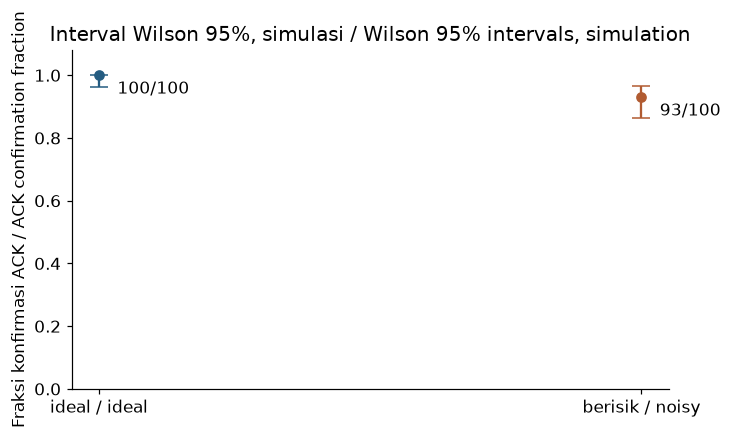

In [7]:
import math
def wilson(correct, total):
    z = 1.959963984540054
    p = correct/total
    center = (p+z*z/(2*total))/(1+z*z/total)
    half = z*math.sqrt(p*(1-p)/total+z*z/(4*total*total))/(1+z*z/total)
    return center-half, center+half
fig, ax = plt.subplots(figsize=(7,4))
for index, (profile, row) in enumerate(summary.iterrows()):
    rate = row['confirmed']/row['trials']
    low, high = wilson(int(row['confirmed']), int(row['trials']))
    ax.errorbar(index, rate, yerr=[[max(0, rate-low)],[max(0, high-rate)]], fmt='o', capsize=6, color=COLORS[index])
    ax.annotate(f'{int(row["confirmed"])}/{int(row["trials"])}', (index, rate), xytext=(12,-12), textcoords='offset points')
ax.set(xticks=[0,1], xticklabels=['ideal / ideal', 'berisik / noisy'], ylim=(0,1.08), ylabel='Fraksi konfirmasi ACK / ACK confirmation fraction',
       title='Interval Wilson 95%, simulasi / Wilson 95% intervals, simulation')
save(fig, 'transport_confirmation')
display(fig); plt.close(fig)


**Bahasa Indonesia**

## Batas eksperimen

Gate, storage, Bell preparation dan distribusi B ideal; noise hanya pada A
dan ACK. Tidak ada hardware, latency, erasure, autentikasi atau enkripsi.
Penerimaan yang belum terkonfirmasi harus tetap dilaporkan terpisah. Tidak
ada fixture rahasia pada decoder: truth hanya dipakai evaluator sesudah
pengukuran, decoding dan verifikasi. Data TCP riil pada mode dua terminal
tetap klasik dan tidak termasuk ledger model quantum di eksperimen in-process.

---

**English**

## Experimental limitations

Gates, storage, Bell preparation, and B distribution are ideal; noise affects only
A and ACK. There is no hardware, latency, erasure, authentication, or encryption.
Unconfirmed receipt must be reported separately. The decoder has no secret fixture:
truth is used only by the evaluator after measurement, decoding, and validation.
Actual TCP in two-terminal mode remains classical and is excluded from the quantum
model ledger in this in-process experiment.


**Bahasa Indonesia**

## Referensi primer dan cara mengutip

1. C. H. Bennett & S. J. Wiesner (1992), *Communication via one- and two-particle
   operators on Einstein-Podolsky-Rosen states*, Physical Review Letters 69, 2881.
   [DOI: 10.1103/PhysRevLett.69.2881](https://doi.org/10.1103/PhysRevLett.69.2881).
2. [IBM Quantum Learning — superdense coding](https://quantum.cloud.ibm.com/learning/en/courses/basics-of-quantum-information/entanglement-in-action/superdense-coding).
3. [IBM Quantum Learning — reduced states](https://quantum.cloud.ibm.com/learning/en/courses/general-formulation-of-quantum-information/density-matrices/multiple-systems).
4. [Google Quantum AI — qsimcirq](https://quantumai.google/qsim/tutorials/qsimcirq),
   [DepolarizingChannel](https://quantumai.google/reference/python/cirq/DepolarizingChannel).

BibTeX ada pada [docs/references.bib](../docs/references.bib), metadata software
pada [CITATION.cff](../CITATION.cff). Tidak ada DOI software atau klaim peer-review.
Notebook ini merupakan penjelasan dan verifikasi numerik protokol yang sudah ada.

---

**English**

## Primary references and citation

1. C. H. Bennett & S. J. Wiesner (1992), *Communication via one- and two-particle
   operators on Einstein-Podolsky-Rosen states*, Physical Review Letters 69, 2881.
   [DOI: 10.1103/PhysRevLett.69.2881](https://doi.org/10.1103/PhysRevLett.69.2881).
2. [IBM Quantum Learning — superdense coding](https://quantum.cloud.ibm.com/learning/en/courses/basics-of-quantum-information/entanglement-in-action/superdense-coding).
3. [IBM Quantum Learning — reduced states](https://quantum.cloud.ibm.com/learning/en/courses/general-formulation-of-quantum-information/density-matrices/multiple-systems).
4. [Google Quantum AI — qsimcirq](https://quantumai.google/qsim/tutorials/qsimcirq),
   [DepolarizingChannel](https://quantumai.google/reference/python/cirq/DepolarizingChannel).

BibTeX is in [docs/references.bib](../docs/references.bib); software metadata is
in [CITATION.cff](../CITATION.cff). No software DOI or peer-review claim is made.
This notebook explains and numerically verifies an established protocol.
